# Sampler comparison — `inox_batch1_doe_compare.yaml`

The design space is read from the config; every generator is pushed through the same unit-cube mapping and scored as
fabricated on four metrics (centered L2 discrepancy ↓, min pairwise distance ↑, max |factor correlation| ↓ with structural
pairs excluded, fill distance ↓ against feasible probe points). Studies: one batch over seeds (§2), cumulative batches (§3),
seed screening (§4), the correlation-weight sweep with its Pareto front (§5), and the chosen design with its run sheet and
figures (§6).

**Nothing is written to disk by default.** Every figure / table cell starts with `SAVE_* = False` and a `*_FILE` name; set a
flag to True to write that one item into `OUT_DIR`.

In [1]:
import os, sys, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PACKAGE_DIR = '/data/zhq7531/IDEAL/DMREF/doe_compare'   # where the doe_compare package lives (None = this repository)
REPO = '/data/zhq7531/IDEAL/DMREF/repository_dmref' or next(p for p in [os.path.abspath('.'), os.path.abspath('..')] if os.path.isdir(os.path.join(p, 'doe_compare')))
sys.path.insert(0, PACKAGE_DIR or REPO); os.chdir(REPO)
import doe_compare as dc
from doe_compare import plots
from doe_compare.metrics import KEYS

CONFIG = 'doe/inox/inox_batch1_doe_compare.yaml'
cfg = dc.load_config(CONFIG); st = cfg['study']; space = dc.space_from_config(cfg)
N, REPS, GUARD = st['n'], st['repetitions'], st['guard']
W = st['corr_weight']                                         # correlation weight carried into the comparisons
WORKERS = st.get('workers')                                   # None = serial; an integer = processes; -1 = every core (results identical)
OUT_DIR = 'output/inox/batch1_doe_compare' or os.path.join('doe_compare_out', 'inox_batch1_doe_compare')   # where SAVE_* flags write (created on first save)
probes = space.probes(st['probes'])
CONSTANTS = cfg.get('constants', {})                      # pinned columns added to the run sheet (not design factors)
REFERENCES = {}                                           # name -> fabricated design read from a file (e.g. the sheet already exported)
for r in cfg.get('references', []):
    _df = pd.read_excel(r['path'], sheet_name=r.get('sheet', 0)); REFERENCES[r['name']] = _df[space.columns].reset_index(drop=True)
REF_METRICS = {name: dc.evaluate(space, d_, probes) for name, d_ in REFERENCES.items()}
KNOWN_DF, KNOWN_SUMMARY = dc.load_known(cfg, space)       # recipes already fabricated / measured that lie inside the bounds (config `known:`)
KNOWN = space.to_unit(KNOWN_DF[space.columns]) if len(KNOWN_DF) else None   # unit points the conditional / sliced optimisers place the batch around
SWEEP_METHOD = 'Sliced LHS' if space.slice_factor else 'LHS: CD + w×|r|'   # the optimiser whose correlation weight is swept in §5 and that builds the design in §6
CATS = [f.name for f in space.factors if f.kind == 'categorical']        # every metric is also reported for the worst level of each of these
CORR_SCOPE = st.get('corr_scope', 'whole')                               # 'whole': the |r| term of the optimisers is the pooled design; 'levels': also every level of every categorical factor
OPT_KW = dict(corr_scope=CORR_SCOPE)
SINGLE_KW = {'LHS: CD + w×|r|': dict(w=W, **OPT_KW), 'Sliced LHS': dict(corr_weight=W, **OPT_KW), 'Optimised LHS + SA': dict(**OPT_KW)}
SEQ_KW = {'Weighted LHS + conditional': dict(w=W, **OPT_KW), 'Sliced LHS, conditional': dict(corr_weight=W, **OPT_KW), 'Optimised LHS + SA, conditional': dict(**OPT_KW)}
with_known = lambda d_: pd.concat([KNOWN_DF[space.columns], d_[space.columns]], ignore_index=True) if KNOWN is not None else d_
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
print(space.name, '|', space.d, 'factors | n =', N, '| repetitions =', REPS, '| known recipes inside the bounds =', len(KNOWN_DF), '| categorical factors scored per level:', CATS, '| nothing is written unless a SAVE_* flag is True')

InOx batch 1 (435-600 C, no RT) | 6 factors | n = 30 | repetitions = 3 | known recipes inside the bounds = 0 | categorical factors scored per level: ['Annealing Condition'] | nothing is written unless a SAVE_* flag is True


## 1. The design space

In [2]:
display(space.describe())
if len(KNOWN_DF):
    display(KNOWN_SUMMARY)                     # per file: recipes, inside the bounds (kept as known locations), dropped
    display(KNOWN_DF.groupby(['source'] + ([space.slice_factor] if space.slice_factor else []), sort=False).size().rename('recipes').to_frame())

,factor,kind,range,step,note
0,Power (W),integer,10 - 30,1,
1,Substrate Temperature (C),integer,435 - 600,1,
2,Oxygen Flow Rate (sccm),continuous,0.3 - 3,0.1,
3,Background Pressure (Torr),continuous,2 - 4,0.1,
4,Annealing Temperature (C),integer,150 - 600,1,
5,Annealing Condition,categorical,N / O,2 levels,"N: 0.5, O: 0.5"
6,Annealing Temperature (C) vs Substrate Tempera...,constraint,Annealing Temperature (C) > Substrate Temperat...,—,upper factor drawn above the realised lower value


## 2. One batch: every generator over seeds

Every metric is scored on the whole batch and, for each categorical factor, on the worst of its levels (the batch split by that factor, each part scored on the other factors): a design can be fine pooled and confounded inside one substrate or one temperature level.

60 designs scored in 3 s


,discrepancy,min_dist,max_corr,fill_dist,corr_Substrate Temperature (C)|Annealing Temperature (C),discrepancy@Annealing Condition,min_dist@Annealing Condition,max_corr@Annealing Condition,fill_dist@Annealing Condition,balance@Annealing Condition
method,,,,,,,,,,
Sobol (scrambled),0.521 ± 0.010,0.265 ± 0.065,0.195 ± 0.061,0.780 ± 0.039,0.669 ± 0.076,0.340 ± 0.013,0.265 ± 0.065,0.298 ± 0.113,0.797 ± 0.055,0.117 ± 0.040
Halton (scrambled),0.526 ± 0.011,0.265 ± 0.044,0.234 ± 0.060,0.857 ± 0.038,0.677 ± 0.047,0.356 ± 0.010,0.265 ± 0.044,0.503 ± 0.085,0.864 ± 0.043,0.209 ± 0.071
Plain LHS,0.526 ± 0.014,0.217 ± 0.050,0.378 ± 0.071,0.876 ± 0.060,0.679 ± 0.088,0.376 ± 0.037,0.217 ± 0.050,0.594 ± 0.129,0.880 ± 0.061,0.288 ± 0.126
Optimised LHS (random-CD),0.518 ± 0.004,0.331 ± 0.041,0.119 ± 0.024,0.805 ± 0.028,0.654 ± 0.012,0.333 ± 0.007,0.331 ± 0.041,0.323 ± 0.093,0.808 ± 0.026,0.113 ± 0.030
LHS: CD + w×|r|,0.518 ± 0.004,0.332 ± 0.022,0.020 ± 0.007,0.780 ± 0.039,0.658 ± 0.033,0.326 ± 0.004,0.332 ± 0.022,0.308 ± 0.081,0.784 ± 0.043,0.019 ± 0.008
Uniform random,0.593 ± 0.053,0.179 ± 0.055,0.338 ± 0.088,0.912 ± 0.065,0.668 ± 0.124,0.442 ± 0.127,0.179 ± 0.055,0.592 ± 0.111,0.916 ± 0.063,0.279 ± 0.108


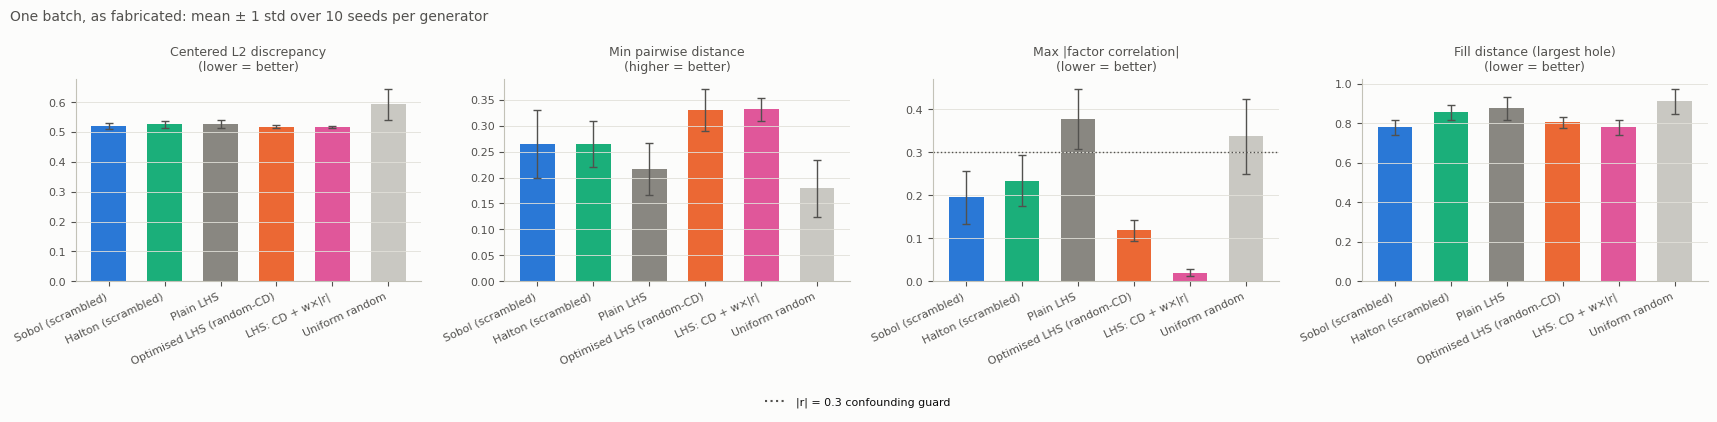

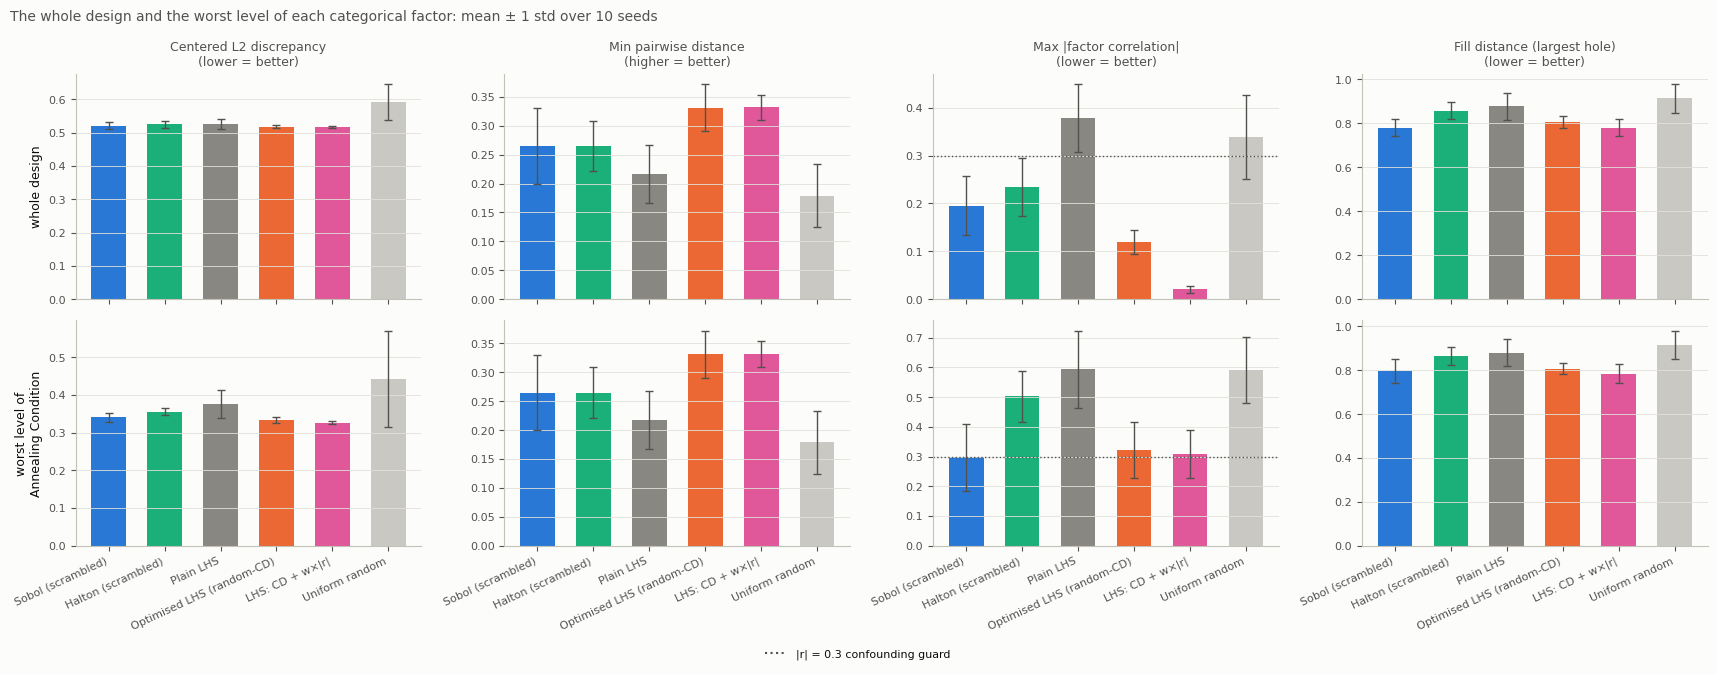

In [3]:
# ---- saving (set a flag to True to write that item)
SAVE_SINGLE_FIG = False;    SINGLE_FIG_FILE = 'single_batch.png'
SAVE_SINGLE_TABLE = False;  SINGLE_TABLE_FILE = 'single_batch.xlsx'
SAVE_SINGLE_LEVELS_FIG = False;  SINGLE_LEVELS_FIG_FILE = 'single_batch_levels.png'

t0 = time.time()
single = dc.single_batch(space, N, st['methods'], range(st['seeds']), probes, SINGLE_KW, workers=WORKERS)
text, best, mean, std = dc.summarize(single)
print(f'{len(single)} designs scored in {time.time() - t0:.0f} s')
display(text.style.apply(lambda col: ['font-weight: bold' if b else '' for b in best[col.name]]) if hasattr(text, 'style') else text)
ref_name = next(iter(REF_METRICS), None)
fig = plots.method_bars(single, star=None if ref_name is None else REF_METRICS[ref_name], star_label=f'reference: {ref_name}')
dc.save_fig(fig, SAVE_SINGLE_FIG, os.path.join(OUT_DIR, SINGLE_FIG_FILE)); plt.show()
if REF_METRICS:
    display(pd.DataFrame(REF_METRICS).T.round(3))
if CATS:
    fig = plots.level_bars(single, CATS); dc.save_fig(fig, SAVE_SINGLE_LEVELS_FIG, os.path.join(OUT_DIR, SINGLE_LEVELS_FIG_FILE)); plt.show()
dc.save_table({'per_seed': single, 'summary': text}, SAVE_SINGLE_TABLE, os.path.join(OUT_DIR, SINGLE_TABLE_FILE))

## 3. Cumulative batches: sequences versus batch generators

90 cumulative designs scored in 12 s


discrepancy  min_dist  max_corr  fill_dist
method                      n_cum                                            
Sobol (scrambled)           30           0.525     0.269     0.223      0.778
                            60           0.512     0.224     0.146      0.674
                            90           0.508     0.185     0.092      0.603
Halton (scrambled)          30           0.524     0.271     0.237      0.847
                            60           0.512     0.199     0.165      0.732
                            90           0.506     0.186     0.116      0.648
Plain LHS                   30           0.529     0.195     0.332      0.879
                            60           0.520     0.122     0.252      0.770
                            90           0.513     0.113     0.185      0.703
Optimised LHS (random-CD)   30           0.517     0.287     0.127      0.823
                            60           0.510     0.137     0.095      0.684
                            90           0.508     0.096     0.089      0.644
Optimised LHS + conditional 30           0.515     0.343     0.112      0.779
                            60           0.509     0.196     0.056      0.672
                            90           0.508     0.165     0.053      0.622
Weighted LHS + conditional  30           0.515     0.334     0.013      0.789
                            60           0.510     0.178     0.007      0.721
                            90           0.509     0.158     0.005      0.643

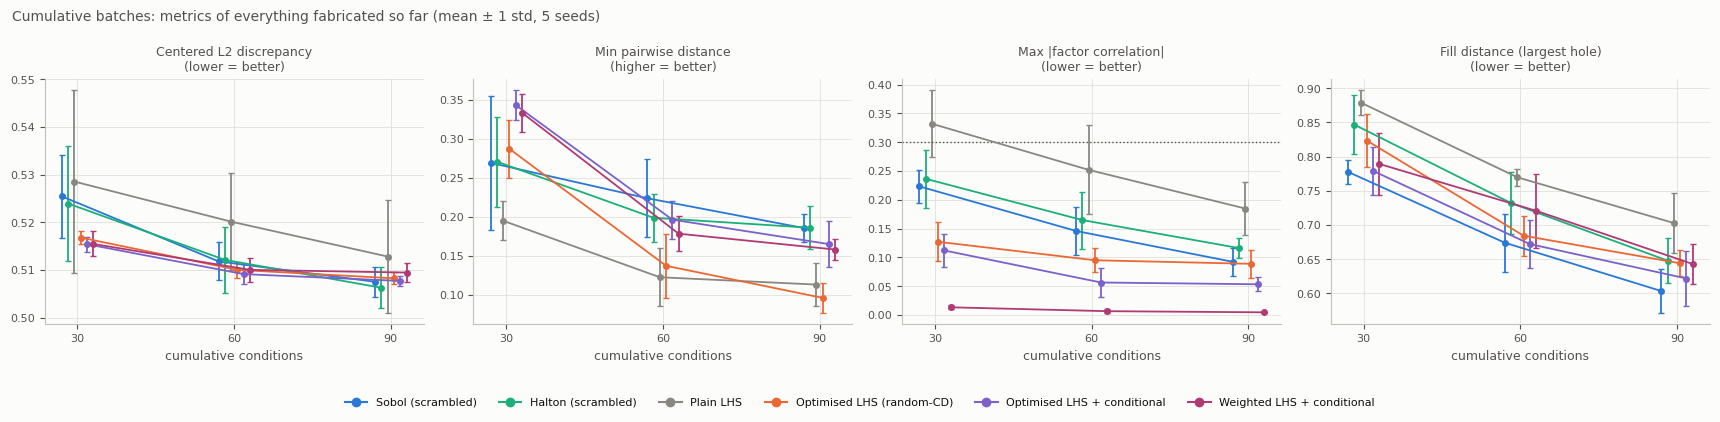

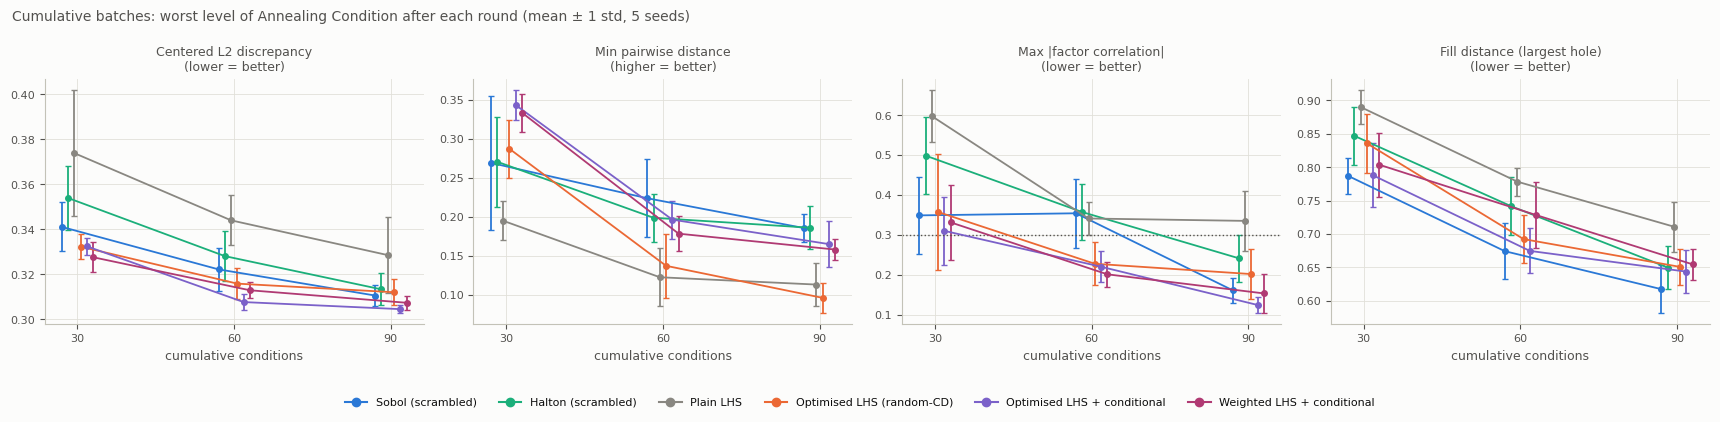

In [4]:
# ---- saving
SAVE_SEQ_FIG = False;    SEQ_FIG_FILE = 'sequential.png'
SAVE_SEQ_TABLE = False;  SEQ_TABLE_FILE = 'sequential.xlsx'
SAVE_SEQ_LEVELS_FIG = False;  SEQ_LEVELS_FIG_FILE = 'sequential_levels_{factor}.png'   # one figure per categorical factor

sq = st['sequential']; t0 = time.time()
seq = dc.sequential(space, N, sq['rounds'], sq['methods'], range(sq['seeds']), KNOWN, probes, SEQ_KW, workers=WORKERS)
print(f'{len(seq)} cumulative designs scored in {time.time() - t0:.0f} s')
seq_summary = seq.groupby(['method', 'n_cum'], sort=False)[KEYS].mean().round(3); display(seq_summary)
fig = plots.sequential_lines(seq); dc.save_fig(fig, SAVE_SEQ_FIG, os.path.join(OUT_DIR, SEQ_FIG_FILE)); plt.show()
for g_ in CATS:                                               # the same rounds, scored on the worst level of each categorical factor
    fig = plots.sequential_lines(seq, scope=g_); dc.save_fig(fig, SAVE_SEQ_LEVELS_FIG, os.path.join(OUT_DIR, SEQ_LEVELS_FIG_FILE.format(factor=''.join(ch if ch.isalnum() else '_' for ch in g_)))); plt.show()
dc.save_table({'per_seed': seq, 'summary': seq_summary}, SAVE_SEQ_TABLE, os.path.join(OUT_DIR, SEQ_TABLE_FILE))

## 4. Seed screening of one generator

Sobol (scrambled): 48 of 50 seeds under the |r| < 0.3 guard on the whole design, 10 also inside every level of every categorical factor; best under the guard by fill distance: seed 48 (fill 0.692, |r| 0.189)


,seed,discrepancy,min_dist,max_corr,fill_dist,max_corr@Annealing Condition,under_guard,under_guard_levels
48,48,0.523,0.298,0.189,0.692,0.400,True,False
7,7,0.512,0.182,0.112,0.713,0.190,True,True
41,41,0.530,0.308,0.147,0.718,0.405,True,False
43,43,0.513,0.339,0.201,0.721,0.407,True,False
28,28,0.519,0.214,0.201,0.726,0.491,True,False
13,13,0.537,0.374,0.194,0.727,0.379,True,False
20,20,0.510,0.227,0.082,0.738,0.389,True,False
16,16,0.520,0.313,0.144,0.746,0.421,True,False
10,10,0.522,0.373,0.171,0.748,0.443,True,False
24,24,0.519,0.334,0.167,0.753,0.398,True,False


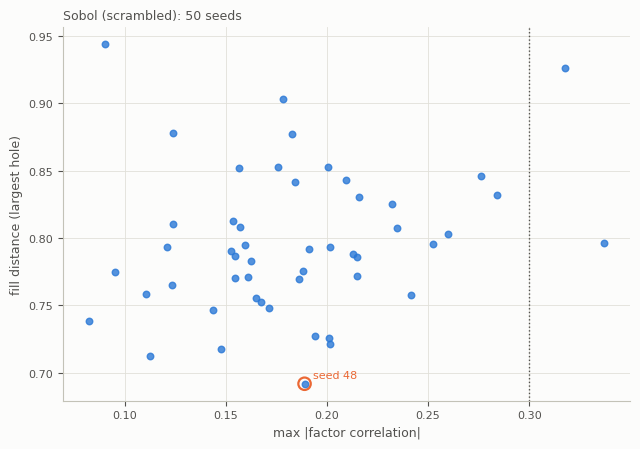

In [5]:
# ---- saving
SAVE_SCREEN_FIG = False;    SCREEN_FIG_FILE = 'seed_screening.png'
SAVE_SCREEN_TABLE = False;  SCREEN_TABLE_FILE = 'seed_screening.xlsx'

sc = st['screen']
screen, best_seed = dc.screen_seeds(space, sc['method'], N, range(sc['seeds']), GUARD, probes, workers=WORKERS, fixed=KNOWN, **SEQ_KW.get(sc['method'], {}))
print(f"{sc['method']}: {int(screen.under_guard.sum())} of {len(screen)} seeds under the |r| < {GUARD:g} guard on the whole design, {int(screen.under_guard_levels.sum())} also inside every level of every categorical factor; "
      + ('no seed under the guard' if best_seed is None else f"best under the guard by fill distance: seed {int(best_seed.seed)} (fill {best_seed.fill_dist:.3f}, |r| {best_seed.max_corr:.3f})"))
display(screen.sort_values('fill_dist').head(10)[['seed'] + KEYS + dc.level_columns(screen.columns, 'max_corr') + ['under_guard', 'under_guard_levels']].round(3))
fig = plots.seed_scatter(screen, pick_seed=None if best_seed is None else int(best_seed.seed), title=f"{sc['method']}: {len(screen)} seeds"); dc.save_fig(fig, SAVE_SCREEN_FIG, os.path.join(OUT_DIR, SCREEN_FIG_FILE)); plt.show()
dc.save_table(screen, SAVE_SCREEN_TABLE, os.path.join(OUT_DIR, SCREEN_TABLE_FILE))

## 5. The correlation-weight sweep: discrepancy + w × |r|, Pareto front and the pick

optimiser: LHS: CD + w×|r| | |r| term scope: whole 
60 weighted designs in 9 s


discrepancy        min_dist        max_corr        fill_dist       
                   mean    std     mean    std     mean    std      mean    std
corr_weight                                                                    
0.00              0.517  0.003    0.329  0.026    0.120  0.035     0.799  0.043
0.02              0.517  0.003    0.322  0.032    0.037  0.010     0.796  0.037
0.05              0.518  0.004    0.291  0.045    0.025  0.010     0.799  0.058
0.10              0.518  0.004    0.332  0.022    0.020  0.007     0.780  0.039
0.20              0.519  0.003    0.312  0.046    0.016  0.005     0.788  0.050
0.50              0.520  0.007    0.311  0.048    0.015  0.004     0.778  0.036

,front_id,corr_weight,seed,fronts,discrepancy,min_dist,max_corr,fill_dist,corr_Substrate Temperature (C)|Annealing Temperature (C),max_corr@Annealing Condition
0,1,0.50,8,"3-objective, corr-vs-discrepancy, corr-vs-fill...",0.524,0.318,0.008,0.816,0.637,0.250
1,2,0.50,7,"3-objective, corr-vs-fill_dist",0.525,0.247,0.009,0.764,0.642,0.263
2,3,0.20,8,"3-objective, corr-vs-discrepancy, corr-vs-min_...",0.517,0.373,0.012,0.769,0.707,0.240
3,4,0.20,1,"3-objective, corr-vs-fill_dist",0.521,0.262,0.012,0.746,0.619,0.217
4,5,0.20,9,"3-objective, corr-vs-discrepancy",0.517,0.361,0.012,0.760,0.629,0.339
5,6,0.20,0,corr-vs-discrepancy,0.515,0.282,0.013,0.837,0.705,0.401
6,7,0.50,0,corr-vs-discrepancy,0.509,0.275,0.013,0.813,0.705,0.240
7,8,0.10,8,"3-objective, corr-vs-fill_dist",0.520,0.368,0.014,0.737,0.696,0.235
8,9,0.10,2,"3-objective, corr-vs-fill_dist",0.525,0.342,0.016,0.717,0.628,0.256
9,10,0.50,9,"3-objective, corr-vs-min_dist",0.512,0.393,0.017,0.784,0.690,0.446


automatic pick: front id 8 (w = 0.1, seed 8)  discrepancy = 0.520, min_dist = 0.368, max_corr = 0.014, fill_dist = 0.737
-> to take another front design, set SELECT in §6 to its front_id (or to a (weight, seed) pair)


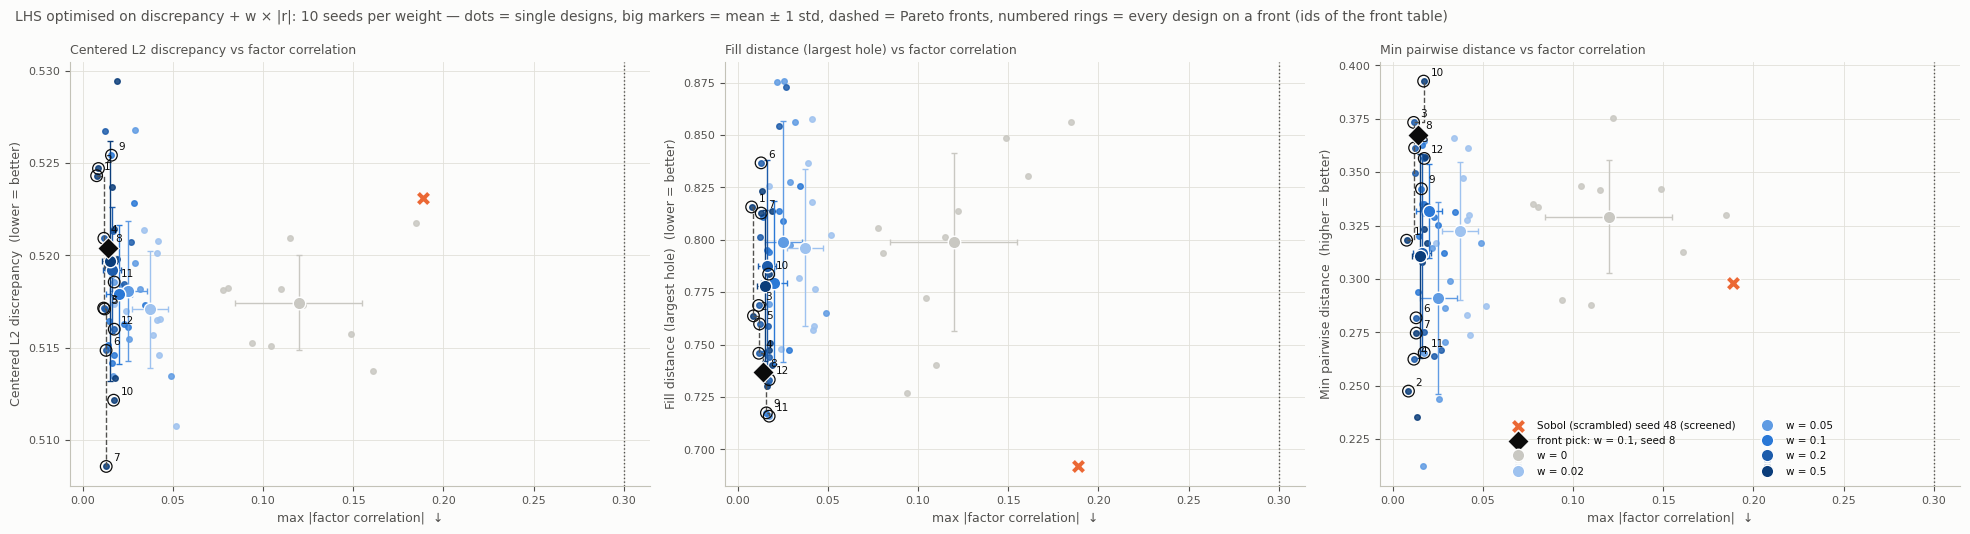

In [6]:
# ---- saving
SAVE_SWEEP_FIG = False;    SWEEP_FIG_FILE = 'corr_weight_pareto.png'
SAVE_SWEEP_TABLE = False;  SWEEP_TABLE_FILE = 'corr_weight_sweep.xlsx'

sw = st['sweep']; t0 = time.time()
sweep, U_store = dc.sweep_corr_weight(space, N, sw['weights'], range(sw['seeds']), probes, sw['n_iter'], fixed=KNOWN, workers=WORKERS, method=SWEEP_METHOD, corr_scope=CORR_SCOPE)
print('optimiser:', SWEEP_METHOD, '| |r| term scope:', CORR_SCOPE, '| metrics on known + new' if KNOWN is not None else '')
print(f'{len(sweep)} weighted designs in {time.time() - t0:.0f} s')
display(sweep.groupby('corr_weight')[KEYS].agg(['mean', 'std']).round(3))
pick = dc.pick_from_front(sweep, st['pick']['max_corr'])
refs = dict(REF_METRICS)
if best_seed is not None:
    refs[f"{sc['method']} seed {int(best_seed.seed)} (screened)"] = best_seed.to_dict()
front = dc.front_table(sweep).round(3)                      # front_id = the number printed next to each ringed design; 'fronts' says which front(s) it is on; max_corr@<factor> = its worst level
display(front)
if pick is not None:
    fid = int(front.loc[(front.corr_weight == pick.corr_weight) & (front.seed == pick.seed), 'front_id'].iloc[0])
    print(f'automatic pick: front id {fid} (w = {pick.corr_weight:g}, seed {int(pick.seed)})  ' + ', '.join(f'{k} = {pick[k]:.3f}' for k in KEYS)
          + '\n-> to take another front design, set SELECT in §6 to its front_id (or to a (weight, seed) pair)')
fig = plots.pareto_tradeoff(sweep, refs=refs, pick=None if pick is None else (float(pick.corr_weight), int(pick.seed)))
dc.save_fig(fig, SAVE_SWEEP_FIG, os.path.join(OUT_DIR, SWEEP_FIG_FILE)); plt.show()
dc.save_table({'per_design': sweep, 'front': front}, SAVE_SWEEP_TABLE, os.path.join(OUT_DIR, SWEEP_TABLE_FILE))

## 6. The chosen design

The choice is yours. `SELECT = None` takes the automatic pick of §5; `SELECT = 7` takes the front design numbered 7 in the
figure and the front table; `SELECT = (0.5, 2)` takes the sweep design with that weight and seed. `CHOICE['method']` can
also name another generator (or, with known recipes, a conditional extender) with its seed. The cell builds the new
recipes, scores them together with the known ones and alone, compares them with the references, draws the pair plot, the
correlation matrix (known + new) and the constraint plane, and prepares the run sheet (repetitions, your column order)
with its provenance.

chosen: {'method': 'LHS: CD + w×|r|', 'w': 0.1, 'seed': 8} | new recipes: 30 | known recipes conditioned on: 0


,discrepancy,min_dist,max_corr,fill_dist,corr_Substrate Temperature (C)|Annealing Temperature (C),discrepancy@Annealing Condition,min_dist@Annealing Condition,max_corr@Annealing Condition,fill_dist@Annealing Condition,balance@Annealing Condition,runs@Annealing Condition
"CHOSEN: LHS: CD + w×|r|, w = 0.1, seed 8",0.520415,0.36753,0.013945,0.736784,0.695841,0.325015,0.36753,0.23543,0.736784,0.013182,15-15
"reference: Sobol (scrambled), screened seed 48",0.52313,0.29805,0.188864,0.691834,0.680182,0.33397,0.29805,0.399997,0.703445,0.070877,15-15


,factor,level,n,discrepancy,min_dist,max_corr,fill_dist
0,(whole design),all,30,0.520,0.368,0.014,0.737
1,Annealing Condition,N,15,0.321,0.368,0.235,0.737
2,Annealing Condition,O,15,0.325,0.449,0.228,0.696


,Power (W),Substrate Temperature (C),Oxygen Flow Rate (sccm),Background Pressure (Torr),Annealing Temperature (C),Annealing Condition
0,22,533,3.0,2.5,544,N
1,15,525,2.4,2.9,594,N
2,13,579,0.6,2.6,596,O
3,27,594,2.0,2.6,598,N
4,25,544,1.1,3.6,577,N
5,19,538,0.6,4.0,577,O
6,30,569,1.3,2.2,577,O
7,14,496,2.8,3.6,586,O
8,28,487,1.8,3.8,575,N
9,11,558,1.6,3.8,571,N


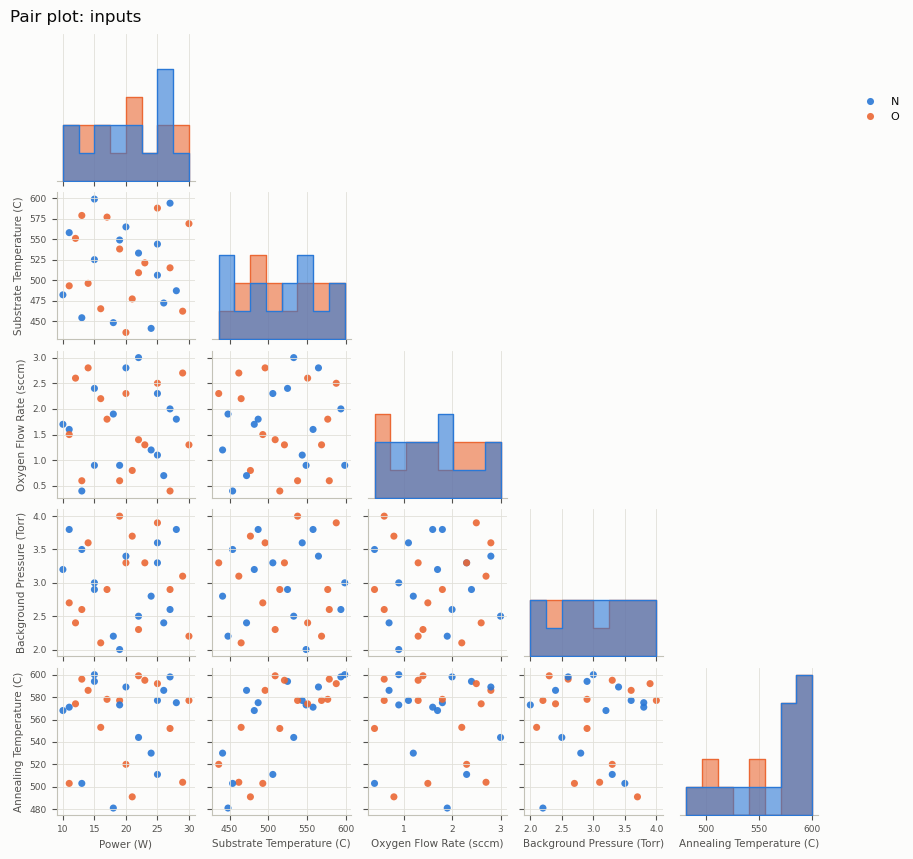

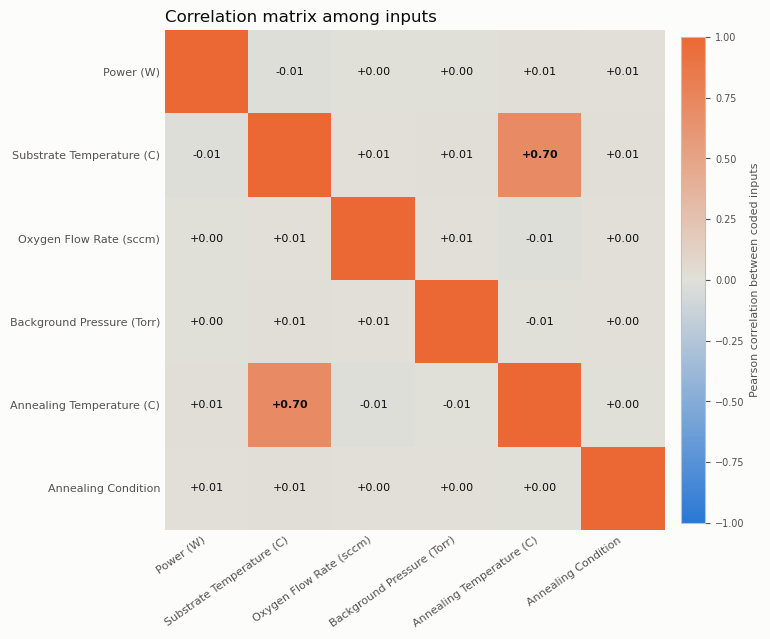

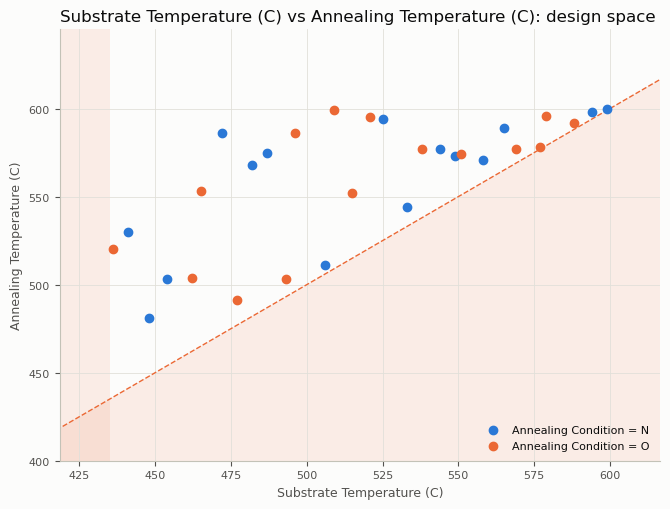

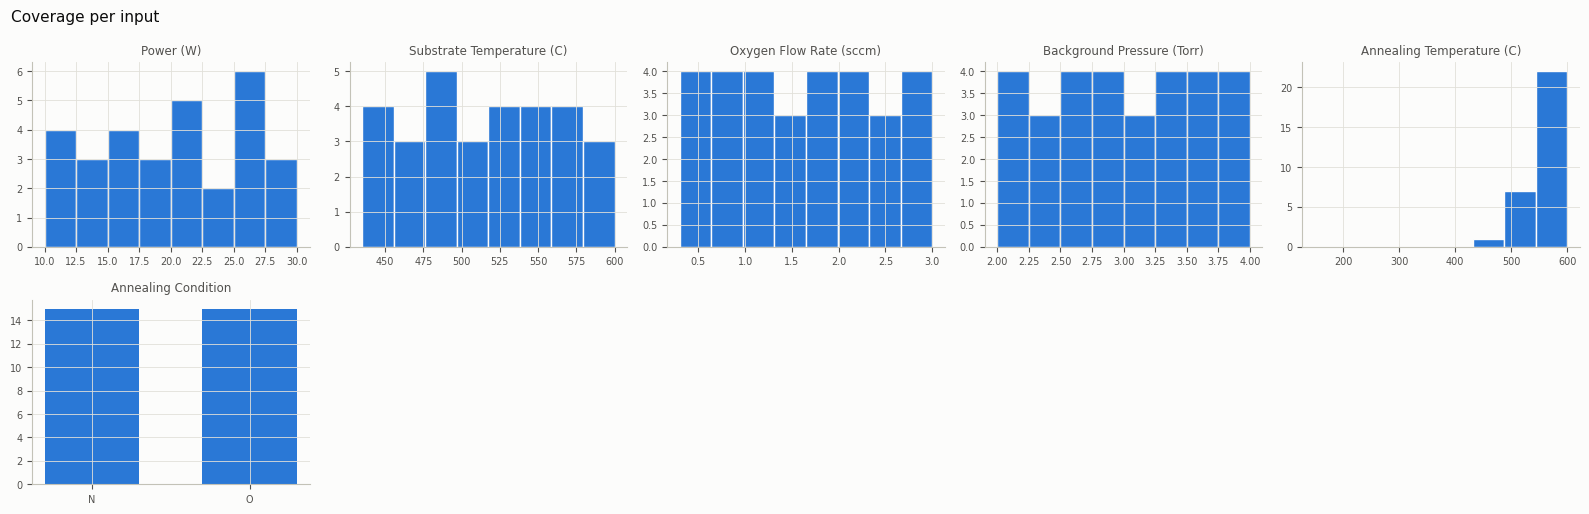

run sheet: 90 rows = 30 conditions x 3 repetitions


,Sample,Repetition,Power (W),Substrate Temperature (C),Oxygen Flow Rate (sccm),Background Pressure (Torr),Annealing Condition,Annealing Temperature (C)
0,1,1,22,533,3.0,2.5,N,544
1,1,2,22,533,3.0,2.5,N,544
2,1,3,22,533,3.0,2.5,N,544
3,2,1,15,525,2.4,2.9,N,594
4,2,2,15,525,2.4,2.9,N,594
5,2,3,15,525,2.4,2.9,N,594


In [7]:
# ---- saving
SAVE_DESIGN_WORKBOOK = False;    DESIGN_WORKBOOK_FILE = 'design.xlsx'
SAVE_DESIGN_PAIRPLOT = False;    DESIGN_PAIRPLOT_FILE = 'design_pairplot.png'
SAVE_DESIGN_CORRELATION = False; DESIGN_CORRELATION_FILE = 'design_correlation.png'
SAVE_DESIGN_CONSTRAINT = False;  DESIGN_CONSTRAINT_FILE = 'design_constraint_plane.png'
SAVE_DESIGN_COVERAGE = False;    DESIGN_COVERAGE_FILE = 'design_coverage.png'
SAVE_DESIGN_LEVELS = False;      DESIGN_LEVELS_FILE = 'design_levels.xlsx'

SELECT = None          # None = the automatic pick of §5; an int = a front_id from the front table / figure; (weight, seed) = any sweep design
CHOICE = dict(method=SWEEP_METHOD, w=None, seed=None)   # or e.g. dict(method='Sobol (scrambled)', w=None, seed=48) to take another generator / extender
if CHOICE['method'] == SWEEP_METHOD:
    w_, seed_, U = dc.select_design(sweep, U_store, SELECT, st['pick']['max_corr']); CHOICE.update(w=w_, seed=seed_)
elif KNOWN is not None and CHOICE['method'] in dc.EXTENDERS:
    U = dc.extend(space, CHOICE['method'], KNOWN, N, CHOICE['seed'], **SEQ_KW.get(CHOICE['method'], {}))
else:
    U = dc.generate(space, CHOICE['method'], N, CHOICE['seed'])
print('chosen:', CHOICE, '| new recipes:', len(U), '| known recipes conditioned on:', 0 if KNOWN is None else len(KNOWN))
design = space.from_unit(U)                                   # the new recipes only
label = f"CHOSEN: {CHOICE['method']}" + (f", w = {CHOICE['w']:g}" if CHOICE['w'] is not None else '') + f", seed {CHOICE['seed']}"
candidates = {label + (' (known + new)' if KNOWN is not None else ''): with_known(design)}
if KNOWN is not None:
    candidates[label + ' (new recipes alone)'] = design
if best_seed is not None:
    ref_U = (dc.extend(space, sc['method'], KNOWN, N, int(best_seed.seed), **SEQ_KW.get(sc['method'], {})) if (KNOWN is not None and sc['method'] in dc.EXTENDERS)
             else dc.generate(space, sc['method'], N, int(best_seed.seed), **SEQ_KW.get(sc['method'], {})))
    candidates[f"reference: {sc['method']}, screened seed {int(best_seed.seed)}"] = with_known(space.from_unit(ref_U))
for name, d_ in REFERENCES.items():
    candidates[f"reference: {name}"] = with_known(d_)
choice_tbl = dc.candidates_table(space, candidates, probes).round(3); display(choice_tbl)
level_tbl = dc.level_table(space, with_known(design), probes).round(3)    # the whole design and every level of every categorical factor, one row each
display(level_tbl); dc.save_table(level_tbl, SAVE_DESIGN_LEVELS, os.path.join(OUT_DIR, DESIGN_LEVELS_FILE))
display(design)

fig = plots.pairplot(design, space); dc.save_fig(fig, SAVE_DESIGN_PAIRPLOT, os.path.join(OUT_DIR, DESIGN_PAIRPLOT_FILE)); plt.show()
fig = plots.correlation_heatmap(with_known(design), space, title='Correlation matrix among inputs' + (f' (known + new, {len(with_known(design))} recipes)' if KNOWN is not None else ''))
dc.save_fig(fig, SAVE_DESIGN_CORRELATION, os.path.join(OUT_DIR, DESIGN_CORRELATION_FILE)); plt.show()
if space.constraints:
    fig = plots.constraint_plane(design, space, ylim=st.get('plane_ylim')); dc.save_fig(fig, SAVE_DESIGN_CONSTRAINT, os.path.join(OUT_DIR, DESIGN_CONSTRAINT_FILE)); plt.show()
fig = plots.coverage_hist(design, space); dc.save_fig(fig, SAVE_DESIGN_COVERAGE, os.path.join(OUT_DIR, DESIGN_COVERAGE_FILE)); plt.show()

m = dc.evaluate(space, with_known(design), probes)       # what the model will see: known + new
for k_, v_ in CONSTANTS.items():
    design[k_] = v_                                          # pinned columns for the sheet
sheet = dc.run_sheet(design, REPS, st['id_col'], st['rep_col'], st['sheet_columns'])
prov = dc.provenance_table(campaign=space.name, config=CONFIG, generator=CHOICE['method'], seed=CHOICE['seed'], corr_weight=CHOICE['w'], corr_scope=CORR_SCOPE,
                           n=N, repetitions=REPS, known=(f'{len(KNOWN_DF)} recipes already in hand, inside the bounds, conditioned on' if KNOWN is not None else 'none'),
                           metrics=('known + new: ' if KNOWN is not None else '') + ', '.join(f'{k} = {v:.3f}' for k, v in m.items() if isinstance(v, float)),
                           written=pd.Timestamp.today().strftime('%Y-%m-%d'))
print(f'run sheet: {len(sheet)} rows = {N} conditions x {REPS} repetitions'); display(sheet.head(6))
dc.save_table({'design_full': sheet, 'design_unique': design, 'config': space.describe(), 'provenance': prov, 'candidates': choice_tbl.rename_axis('design').reset_index(),
               'levels': level_tbl, **({'known_recipes': KNOWN_DF} if KNOWN is not None else {})},
              SAVE_DESIGN_WORKBOOK, os.path.join(OUT_DIR, DESIGN_WORKBOOK_FILE))

## 7. Reading the results

Use the tables and figures above to answer, for this design space: which generator is best for one batch (§2), which keeps
spacing and holes as batches accumulate (§3), how much the seed matters (§4), what the correlation penalty buys and costs (§5),
and whether the chosen design (§6) clears the |r| guard with the structural pairs reported separately. Write the verdict here.